# Ass4 — Red Wine Outlier Detection
**Principles of AI | Lab 2 — Question 2**

We will detect unusual wines using **IQR** and **Isolation Forest**, compare their results, and change one model parameter at a time.

**How to run:** choose **Runtime → Run all**. The dataset loads automatically; no upload or account key is needed.

The workflow follows the Section 4 example prepared by **Eng. Samaa Abdelmohsen**, reorganized into functions and explained step by step. Unlike the broader section example, this assignment excludes `quality` from detection and does not require Z-score.

> The question calls the tree method “Random Forest.” The requested estimator is **IsolationForest**, an unsupervised outlier detector, not a RandomForestClassifier.

# Import Libraries
`pandas` handles tables, `numpy` helps compare predictions, and `matplotlib` draws the boxplots. `IsolationForest` detects unusual rows. We keep `StandardScaler` to follow the section example.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)

# Load the Dataset
The same Red Wine Quality dataset is available from UCI. If the CSV is already beside this notebook, we read the local copy. `sep=None` detects commas or semicolons, as in the section code.

In [2]:
def load_data(filename="winequality-red.csv"):
    url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
    source = filename if Path(filename).is_file() else url
    return pd.read_csv(source, sep=None, engine="python")


df = load_data()
print("Rows and columns:", df.shape)
display(df.head())

Rows and columns: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


# Explore the Data
Before detecting outliers, we check the column names, data types, and missing values. This also helps us confirm that the file loaded correctly.

In [3]:
print("Column names:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame("Data type"))
print("Missing values:")
display(df.isna().sum().to_frame("Missing values"))
print("Total missing cells:", int(df.isna().sum().sum()))
display(df.describe().round(3))

Column names:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']

Data types:


,Data type
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64


Missing values:


,Missing values
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


Total missing cells: 0


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000,1599.000
mean,8.320,0.528,0.271,2.539,0.087,15.875,46.468,0.997,3.311,0.658,10.423,5.636
std,1.741,0.179,0.195,1.410,0.047,10.460,32.895,0.002,0.154,0.170,1.066,0.808
min,4.600,0.120,0.000,0.900,0.012,1.000,6.000,0.990,2.740,0.330,8.400,3.000
25%,7.100,0.390,0.090,1.900,0.070,7.000,22.000,0.996,3.210,0.550,9.500,5.000
50%,7.900,0.520,0.260,2.200,0.079,14.000,38.000,0.997,3.310,0.620,10.200,6.000
75%,9.200,0.640,0.420,2.600,0.090,21.000,62.000,0.998,3.400,0.730,11.100,6.000
max,15.900,1.580,1.000,15.500,0.611,72.000,289.000,1.004,4.010,2.000,14.900,8.000


# Select the Features
We use all numeric input columns and leave out `quality`, as required. IQR uses the original values. For Isolation Forest, we standardize the same features to match the section workflow; scaling is not a general requirement of Isolation Forest.

In [4]:
def prepare_features(data):
    features = data.drop(columns=["quality"]).select_dtypes(include="number")
    if features.isna().any().any():
        raise ValueError("Handle missing feature values before detection.")
    scaled = pd.DataFrame(
        StandardScaler().fit_transform(features),
        columns=features.columns,
        index=features.index,
    )
    return features, scaled


X, X_scaled = prepare_features(df)
n_rows = len(df)
print("Number of rows:", n_rows)
print("Detection features:", X.columns.tolist())
print("Is quality included?", "quality" in X.columns)

Number of rows: 1599
Detection features: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']
Is quality included? False


# Method 1 — IQR Detection
For each feature, we calculate the first quartile, third quartile, and their difference: `IQR = Q3 - Q1`.

The limits are `Q1 - 1.5 × IQR` and `Q3 + 1.5 × IQR`. A row is an outlier if **at least one** feature falls outside its limits. We use `.any(axis=1)` so a row is counted only once.

In [5]:
def detect_iqr(features):
    q1 = features.quantile(0.25)
    q3 = features.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    flags = (features < lower) | (features > upper)
    mask = flags.any(axis=1)
    details = pd.DataFrame({
        "Q1": q1, "Q3": q3, "IQR": iqr,
        "Lower bound": lower, "Upper bound": upper,
        "Outliers": flags.sum(),
    })
    return mask, details


iqr_mask, iqr_details = detect_iqr(X)
print("IQR bounds and outliers per feature:")
display(iqr_details.round(4))
print("IQR outlier rows:", int(iqr_mask.sum()))

IQR bounds and outliers per feature:


,Q1,Q3,IQR,Lower bound,Upper bound,Outliers
fixed acidity,7.1000,9.2000,2.1000,3.9500,12.3500,49
volatile acidity,0.3900,0.6400,0.2500,0.0150,1.0150,19
citric acid,0.0900,0.4200,0.3300,-0.4050,0.9150,1
residual sugar,1.9000,2.6000,0.7000,0.8500,3.6500,155
chlorides,0.0700,0.0900,0.0200,0.0400,0.1200,112
free sulfur dioxide,7.0000,21.0000,14.0000,-14.0000,42.0000,30
total sulfur dioxide,22.0000,62.0000,40.0000,-38.0000,122.0000,55
density,0.9956,0.9978,0.0022,0.9922,1.0012,45
pH,3.2100,3.4000,0.1900,2.9250,3.6850,35
sulphates,0.5500,0.7300,0.1800,0.2800,1.0000,59


IQR outlier rows: 405


# Method 2 — Isolation Forest
Isolation Forest builds random trees to isolate observations. Unusual observations tend to be isolated sooner.

We start with the assignment's settings: **100 trees**, **0.05 contamination**, and **random_state=42**. The predicted label is `-1` for an outlier and `1` for a normal row.

In [6]:
def detect_isolation_forest(features, n_estimators=100,
                            contamination=0.05, max_samples="auto"):
    model = IsolationForest(
        n_estimators=n_estimators,
        contamination=contamination,
        max_samples=max_samples,
        random_state=42,
    )
    labels = model.fit_predict(features)
    mask = pd.Series(labels == -1, index=features.index)
    return mask, labels, model


if_mask, if_labels, baseline_model = detect_isolation_forest(X_scaled)
print("Isolation Forest outliers (-1):", int(if_mask.sum()))
print("Normal rows (1):", int((if_labels == 1).sum()))

Isolation Forest outliers (-1): 80
Normal rows (1): 1519


# Compare the Two Methods
We compare the number of outlier rows and their percentage of the entire dataset:

**Percentage = (outlier rows ÷ total rows) × 100**

The counts do not have to match. IQR checks each feature separately, while Isolation Forest considers the features together. Neither count alone tells us which method is more accurate.

In [7]:
def comparison_table(masks, total_rows):
    rows = []
    for method, parameters, mask in masks:
        count = int(mask.sum())
        rows.append({
            "Method": method,
            "Parameters": parameters,
            "Number of outliers": count,
            "Percentage (%)": round(count / total_rows * 100, 2),
        })
    return pd.DataFrame(rows)


comparison = comparison_table([
    ("IQR", "1.5 × IQR", iqr_mask),
    ("Isolation Forest", "n_estimators=100, contamination=0.05, max_samples=auto", if_mask),
], n_rows)
display(comparison)
print("Rows detected by both methods:", int((iqr_mask & if_mask).sum()))

,Method,Parameters,Number of outliers,Percentage (%)
0,IQR,1.5 × IQR,405,25.33
1,Isolation Forest,"n_estimators=100, contamination=0.05, max_samp...",80,5.00


Rows detected by both methods: 79


# Change One Parameter at a Time
Each group keeps the other settings at their baseline values:
- **n_estimators:** 50, 100, 200 — change the number of trees.
- **contamination:** 0.01, 0.05, 0.10 — change the expected outlier proportion.
- **max_samples:** 128, 256, 'auto' — change the samples used by each tree.

We keep the random seed fixed. Each group includes its baseline for an easy comparison. `Different labels vs baseline` also shows whether the selected rows changed even when the total count stayed the same.

In [8]:
def parameter_experiments(features, baseline_mask):
    baseline = {"n_estimators": 100, "contamination": 0.05, "max_samples": "auto"}
    groups = {
        "n_estimators": [50, 100, 200],
        "contamination": [0.01, 0.05, 0.10],
        "max_samples": [128, 256, "auto"],
    }
    results = []
    for parameter, values in groups.items():
        for value in values:
            settings = baseline.copy()
            settings[parameter] = value
            mask, _, _ = detect_isolation_forest(features, **settings)
            count = int(mask.sum())
            results.append({
                "Changed parameter": parameter,
                **settings,
                "Number of outliers": count,
                "Percentage (%)": round(count / len(features) * 100, 2),
                "Different labels vs baseline": int(np.count_nonzero(
                    mask.to_numpy() != baseline_mask.to_numpy()
                )),
            })
    return pd.DataFrame(results)


experiments = parameter_experiments(X_scaled, if_mask)
display(experiments)

,Changed parameter,n_estimators,contamination,max_samples,Number of outliers,Percentage (%),Different labels vs baseline
0,n_estimators,50,0.05,auto,79,4.94,21
1,n_estimators,100,0.05,auto,80,5.00,0
2,n_estimators,200,0.05,auto,80,5.00,16
3,contamination,100,0.01,auto,16,1.00,64
4,contamination,100,0.05,auto,80,5.00,0
5,contamination,100,0.10,auto,159,9.94,79
6,max_samples,100,0.05,128,80,5.00,20
7,max_samples,100,0.05,256,80,5.00,0
8,max_samples,100,0.05,auto,80,5.00,0


# Explain the Results
The following four lines summarize the actual experiment results. Contamination mainly controls how many rows are labelled as outliers; the other settings can change which rows are selected.

In [9]:
contamination_runs = experiments[experiments["Changed parameter"] == "contamination"]
minimum = int(contamination_runs["Number of outliers"].min())
maximum = int(contamination_runs["Number of outliers"].max())
print(f"1. Contamination had the largest effect on the count: from {minimum} to {maximum} outliers.")
print("2. It changes the decision threshold to match the expected proportion of outliers.")
print("3. Changing the number of trees can change the selected rows, even if the total count stays the same.")
print("4. Changing max_samples can change the selected rows; auto uses 256 samples here, so it matches 256.")

1. Contamination had the largest effect on the count: from 16 to 159 outliers.
2. It changes the decision threshold to match the expected proportion of outliers.
3. Changing the number of trees can change the selected rows, even if the total count stays the same.
4. Changing max_samples can change the selected rows; auto uses 256 samples here, so it matches 256.


# Bonus — Feature Boxplots
Each feature has its own boxplot because the features have different units and ranges. Points beyond the whiskers show potential IQR outliers. The `quality` column is still excluded.

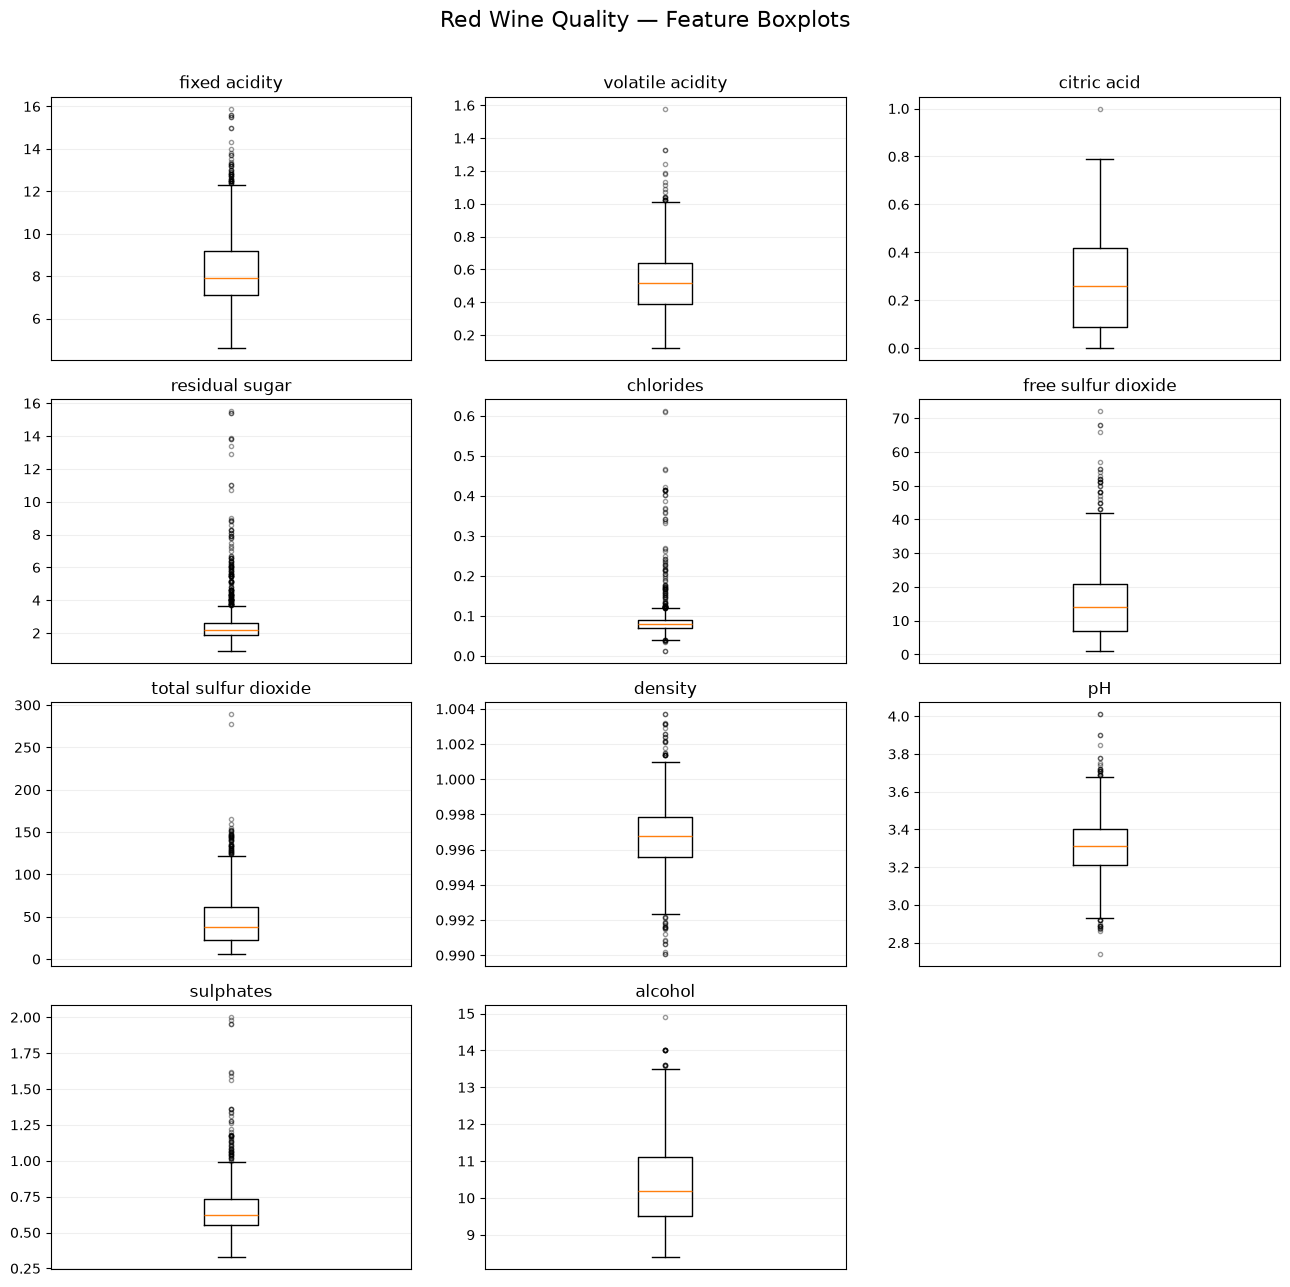

In [10]:
fig, axes = plt.subplots(4, 3, figsize=(13, 13))
for ax, column in zip(axes.flat, X.columns):
    ax.boxplot(X[column], flierprops={"markersize": 3, "alpha": 0.4})
    ax.set_title(column)
    ax.set_xticks([])
    ax.grid(axis="y", alpha=0.2)
for ax in list(axes.flat)[len(X.columns):]:
    ax.set_visible(False)
fig.suptitle("Red Wine Quality — Feature Boxplots", fontsize=16)
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

# Conclusion
IQR identifies rows with extreme values in individual features. Isolation Forest finds unusual combinations across features. Contamination has the clearest effect on the number of detected outliers, while the tree and sample settings can affect their identities.

We only **detect and compare** outliers here; we do not automatically delete them. An unusual wine is not necessarily a data error.

### Sources
- Course Section 4 code and explanation by **Eng. Samaa Abdelmohsen**, adapted to the Ass4 requirements. Original course handouts are not republished.
- Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009). *Wine Quality*. UCI Machine Learning Repository. DOI: **10.24432/C56S3T**. Dataset license: **CC BY 4.0**.
- Dataset: https://archive.ics.uci.edu/dataset/186/wine+quality